 # First pipeline


### Imports + paths

In [2]:
%matplotlib widget

import os
import json
import numpy as np
import cv2 as cv2 
from skimage import io
from matplotlib import pyplot as plt

#paths
SRC = f"../data/pedestrians/input"

FRAMES_dir = f"../data/pedestrians/frames"

## IMSHOW

In [3]:
def imshow(
    images: list[np.ndarray] | np.ndarray,
    titles: list[str] | str | None = None,
    nrows: int = 0,
    ncols: int = 0,
    figsize: (float, float) = (10, 4),
):
    """Plot a multiple images with titles.

    Parameters
    ----------
    images : image list
    titles : title list
    ncols : number of columns of subplots wanted in the display
    nrows : number of rows of subplots wanted in the figure
    figsize : size of the figure
    """
    if not isinstance(images, list):
        images = [images]
    if titles is not None and not isinstance(titles, list):
        titles = [titles]

    if ncols == 0 and nrows == 0:
        ncols = len(images)
        nrows = 1
    if ncols == 0:
        ncols = len(images) // nrows
    if nrows == 0:
        nrows = len(images) // ncols

    fig, axeslist = plt.subplots(
        ncols=ncols, nrows=nrows, squeeze=False, figsize=figsize
    )

    for i, image in enumerate(images):
        axeslist.ravel()[i].imshow(image, cmap=plt.gray(), vmin=0, vmax=255)
        if titles is not None:
            axeslist.ravel()[i].set_title(titles[i])
        axeslist.ravel()[i].set_axis_off()
    plt.tight_layout()  # optional

    return fig, axeslist


## Read frames

In [4]:
#check if it is a video :
def is_video(source):
    return source.endswith((".mp4", ".mov", ".avi"))

#open a video : cv2.VideoCapture(source)
#close a video : video.release()
#read a frame : video.read()
#go at k-th frame : video.set(cv2.CAP_PROP_POS_FRAMES, k)  

#count number of frames
def count_frames(source):
    if is_video(source):
        video = cv2.VideoCapture(source)
        n = int(video.get(cv2.CAP_PROP_FRAME_COUNT))
        video.release()
        return n
    return len(os.listdir(source)) #count files if not a video

#read the k-th frame
def read_frame(source, k):
    if is_video(source):
        video = cv2.VideoCapture(source)
        video.set(cv2.CAP_PROP_POS_FRAMES, k)
        _, frame = video.read()
        video.release()
        return cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    #else : take the list of frames
    names = sorted(os.listdir(source))
    return io.imread(f"{source}/{names[k]}")

## Read an image

In [5]:
nb_frames = count_frames(SRC)
image = read_frame(SRC, 0)

print(nb_frames)
print(image.shape)

1099
(240, 360, 3)


### One image

(<Figure size 1000x400 with 1 Axes>,
 array([[<Axes: title={'center': 'image 0'}>]], dtype=object))

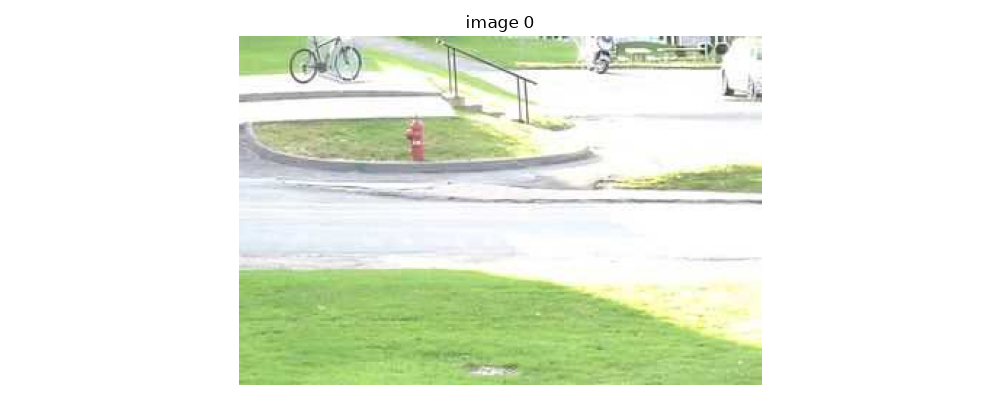

In [6]:
imshow(image, "image 0")

# Get a movement with SAM 2

In [7]:
FIRST = 306
COUNT = 100
STEP = 1

### Create frames dir

In [8]:
for i in range(COUNT) : 
    k = FIRST + i*STEP
    if k >= nb_frames : 
        break

    frame = read_frame(SRC, k)
    io.imsave(f"{FRAMES_dir}/{i}.jpg", frame)

print(len(os.listdir(FRAMES_dir)))


100


Frame source : in000325.jpg


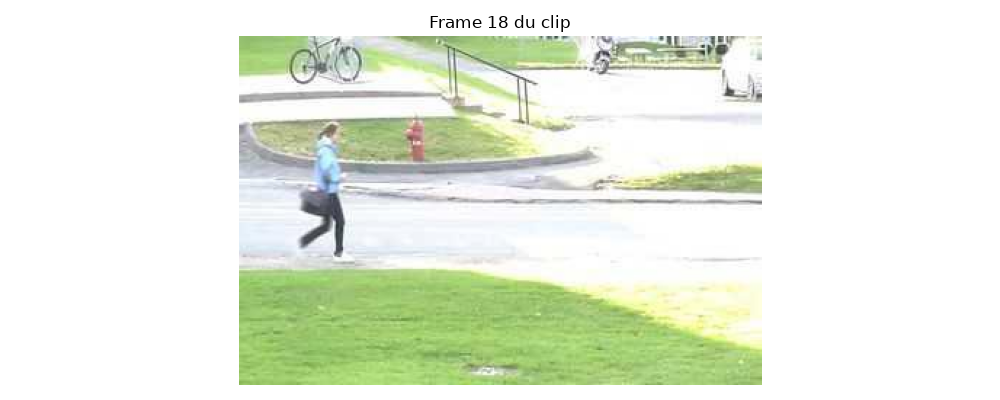

In [9]:
PROMPT_IDX = 18
prompt_frame = read_frame(FRAMES_dir, PROMPT_IDX)
imshow(prompt_frame, f"Frame {PROMPT_IDX} du clip")
print(f"Frame source : in{FIRST + PROMPT_IDX + 1:06d}.jpg")

TODO : 
- click on object : show one frame, click on the pedestrian, save position in a .json
- SAM 2 : load the model, give the frame + click to track the object in all frames
- color the object in red in every framen save the res in outputs/
